Pre-analysis of raw files before loading into MySQL

In [35]:
import pandas as pd

In [36]:
# Load csv files

orders = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_orders_dataset.csv')

In [37]:
customers = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_customers_dataset.csv')
items = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_order_items_dataset.csv')
payments = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_order_payments_dataset.csv')
reviews = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_order_reviews_dataset.csv')
products = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_products_dataset.csv')
sellers = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_sellers_dataset.csv')
categories = pd.read_csv('../data/raw/olist_trimmed_1500_relational/product_category_name_translation.csv')
geolocation = pd.read_csv('../data/raw/olist_trimmed_1500_relational/olist_geolocation_dataset.csv')

In [38]:
# Inspect the shape of every table

tables = {
    "orders": orders,
    "customers": customers,
    "items": items,
    "payments": payments,
    "reviews": reviews,
    "products": products,
    "sellers": sellers,
    "categories": categories,
    "geolocation": geolocation,
}

for name, df in tables.items():
    print(name, df.shape)

orders (1208, 8)
customers (1208, 5)
items (1500, 7)
payments (1303, 5)
reviews (1298, 7)
products (1096, 9)
sellers (494, 4)
categories (57, 2)
geolocation (956, 5)


In [39]:
 # Inspect column names and sample records

for name, df in tables.items():
    print(f"\n{name}")
    print(df.columns.tolist())


orders
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

customers
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

items
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

payments
['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

reviews
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

products
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

sellers
['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

categories
['product_category_name

In [40]:
# Check data types

for name, df in tables.items():
    print(f"\n{name}")
    print(df.dtypes)


orders
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

customers
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

items
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

payments
order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64
dtype: object

reviews
review_id                    str
order_id               

In [41]:
#  Inspect missing values

for name, df in tables.items():
    missing = df.isna().sum()
    print(f"\n{name}")
    print(missing[missing > 0])


orders
order_approved_at    1
dtype: int64

customers
Series([], dtype: int64)

items
Series([], dtype: int64)

payments
Series([], dtype: int64)

reviews
review_comment_title      1200
review_comment_message     774
dtype: int64

products
product_category_name         28
product_name_lenght           28
product_description_lenght    28
product_photos_qty            28
dtype: int64

sellers
Series([], dtype: int64)

categories
Series([], dtype: int64)

geolocation
Series([], dtype: int64)


In [42]:
# Check duplicates

for name, df in tables.items():
    print(name, "duplicate rows:", df.duplicated().sum())

orders duplicate rows: 0
customers duplicate rows: 0
items duplicate rows: 0
payments duplicate rows: 0
reviews duplicate rows: 0
products duplicate rows: 0
sellers duplicate rows: 0
categories duplicate rows: 0
geolocation duplicate rows: 0


In [43]:
print(orders["order_id"].duplicated().sum())
print(customers["customer_id"].duplicated().sum())
print(products["product_id"].duplicated().sum())
print(sellers["seller_id"].duplicated().sum())
print(reviews["review_id"].duplicated().sum())

0
0
0
0
135


In [44]:
# Parse and inspect dates
# Convert order timestamp columns to datetime:

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

In [45]:
print("Min:")
print(orders[date_columns].min())
print()
print("Max:")
print(orders[date_columns].max())

Min:
order_purchase_timestamp        2016-10-03 09:44:50
order_approved_at               2016-10-06 11:43:20
order_delivered_carrier_date    2016-10-10 16:03:01
order_delivered_customer_date   2016-10-13 16:03:46
order_estimated_delivery_date   2016-10-27 00:00:00
dtype: datetime64[us]

Max:
order_purchase_timestamp        2018-08-28 10:57:13
order_approved_at               2018-08-28 11:10:23
order_delivered_carrier_date    2018-08-28 15:26:00
order_delivered_customer_date   2018-08-30 23:38:26
order_estimated_delivery_date   2018-10-25 00:00:00
dtype: datetime64[us]


In [46]:
# Inspect categorical values

print(orders["order_status"].value_counts())
print()
print(payments["payment_type"].value_counts())
print()
print(reviews["review_score"].value_counts().sort_index())

order_status
delivered    1208
Name: count, dtype: int64

payment_type
credit_card    907
boleto         262
voucher        126
debit_card       8
Name: count, dtype: int64

review_score
1     88
2     25
3     99
4    221
5    865
Name: count, dtype: int64


In [47]:
# Profile numeric columns

print(items[["price", "freight_value"]].describe())
print()
print(payments[["payment_value", "payment_installments"]].describe())
print()
print(reviews[["review_score"]].describe())

             price  freight_value
count  1500.000000    1500.000000
mean    102.690747      18.870780
std     168.946666      12.972272
min       2.900000       0.000000
25%      35.000000      12.825000
50%      69.900000      16.110000
75%     129.000000      20.102500
max    4399.870000     196.940000

       payment_value  payment_installments
count    1303.000000           1303.000000
mean      140.033477              3.029163
std       207.844968              2.942210
min         0.000000              1.000000
25%        49.000000              1.000000
50%        89.750000              1.000000
75%       164.405000              4.000000
max      4513.320000             21.000000

       review_score
count   1298.000000
mean       4.348228
std        1.144394
min        1.000000
25%        4.000000
50%        5.000000
75%        5.000000
max        5.000000


In [48]:
# Check relationship coverage

# print(set(orders["order_id"]) - set(customers["customer_id"]))
print(items["order_id"].isin(orders["order_id"]).value_counts())
print(items["product_id"].isin(products["product_id"]).value_counts())
print(items["seller_id"].isin(sellers["seller_id"]).value_counts())

order_id
True    1500
Name: count, dtype: int64
product_id
True    1500
Name: count, dtype: int64
seller_id
True    1500
Name: count, dtype: int64


In [49]:
# Analyze customer identity correctly

print("Customer records:", customers["customer_id"].nunique())
print("Unique people:", customers["customer_unique_id"].nunique())

Customer records: 1208
Unique people: 539


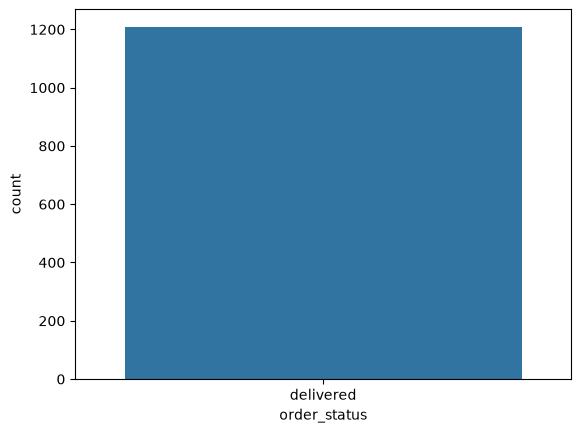

In [50]:
# Order-status count plot

import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=orders, x="order_status")
plt.show()

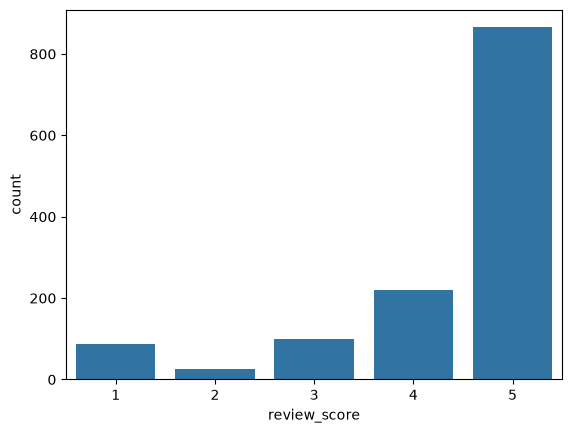

In [51]:
# Review-score distribution

sns.countplot(data=reviews, x="review_score")
plt.show()

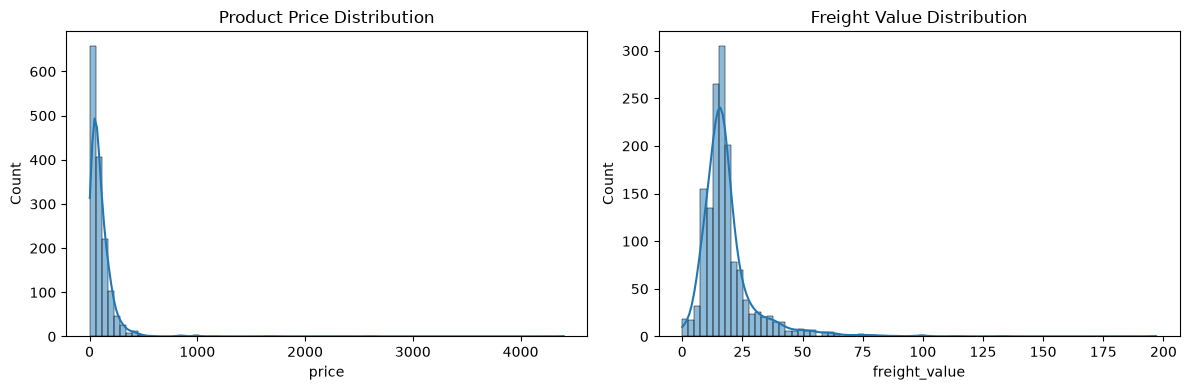

In [52]:
# Price and freight distributions

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(items["price"], kde=True, ax=axes[0])
axes[0].set_title("Product Price Distribution")

sns.histplot(items["freight_value"], kde=True, ax=axes[1])
axes[1].set_title("Freight Value Distribution")

plt.tight_layout()
plt.show()

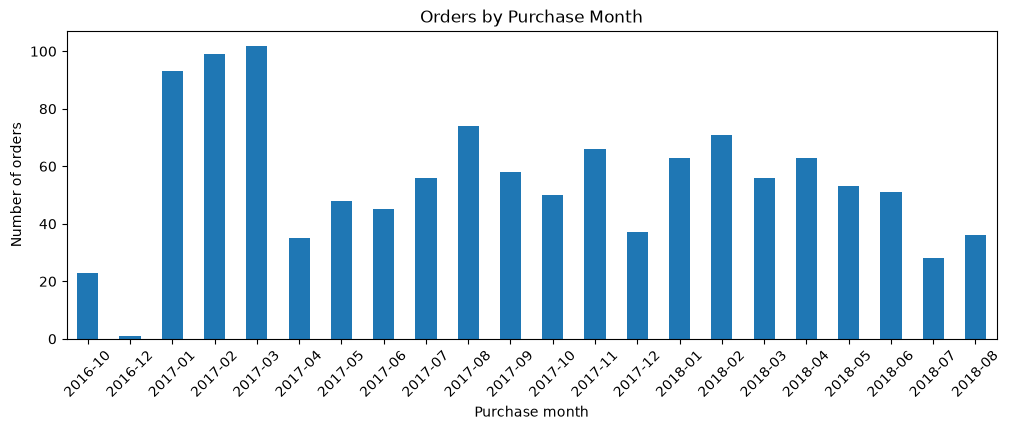

In [53]:
# Monthly order volume

orders["purchase_month"] = (
    orders["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_orders = orders["purchase_month"].value_counts().sort_index()

monthly_orders.plot(kind="bar", figsize=(12, 4))
plt.title("Orders by Purchase Month")
plt.xlabel("Purchase month")
plt.ylabel("Number of orders")
plt.xticks(rotation=45)
plt.show()

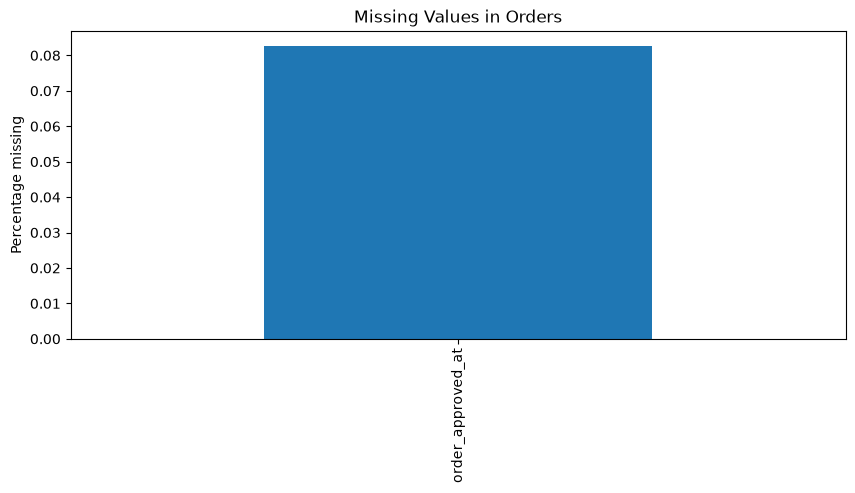

In [54]:
# Missing-value pattern

missing_percent = (
    orders.isna()
    .mean()
    .sort_values(ascending=False)
    .mul(100)
)

missing_percent[missing_percent > 0].plot(kind="bar", figsize=(10, 4))
plt.title("Missing Values in Orders")
plt.ylabel("Percentage missing")
plt.show()